# Cohortes fuera de tiempo: PD de pymes por cosecha a través de 2008 (C03)

**Pregunta:** ¿Se mantiene calibrada una tarjeta de puntaje de PD de pequeñas empresas entrenada antes de la crisis de 2008 sobre los créditos aprobados después de ella, y qué pruebas de la batería lo dicen, en qué dirección?

- **Nivel:** 2, El método en la práctica
- **Requisitos previos:** los notebooks 01 a 03 de este tema
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este notebook puedes:

- explicar por qué un panel de créditos se valida por añada, fuera de tiempo, y por qué el objetivo de una añada se lee solo en su marca de 5 años;
- leer las cinco ventanas móviles de entrenamiento de C03 y ver que cada una cierra antes de que se apruebe su cohorte de prueba;
- leer la PD a 5 años observada y predicha de quince años de aprobación y la calibración por decil;
- llamar a las pruebas de nivel, chi cuadrado, semáforo, multiperíodo y conteo crítico del motor sobre las añadas, y decir por qué las pruebas de una cola siguen en verde mientras la tarjeta de puntaje sobrestima el riesgo.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este notebook, con las mismas versiones exactas:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La siguiente celda importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from datetime import date

from riskvalidation.validation.calibration import critical_default_count, pd_binomial_vasicek, pd_chi2_grades
from riskvalidation.validation.calibration import pd_default_profile, pd_jeffreys, pd_jeffreys_grades
from riskvalidation.validation.calibration import pd_normal_multiperiod, pd_traffic_lights
from matplotlib.colors import ListedColormap

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

El caso C03 es la PD de créditos de pequeñas empresas por añada. Los datos son el archivo FOIA de créditos 7(a) de la Small Business Administration de EE. UU. (dueño: SBA de EE. UU.; licencia "U.S. Government Works", clase `mirror-allowed`; https://data.sba.gov/dataset/7a-504-foia; créditos aprobados desde el año fiscal 1991, al 2026-06-30). Es un programa federal de garantía para créditos de pequeñas empresas, no la cartera pyme de un banco: el archivo no tiene historial de mora, saldo ni clasificación (hallazgo `F-DATA`). La cadena de cálculo ajustó seis modelos con los años fiscales de aprobación hasta una fecha de corte y puntuó cinco cohortes posteriores. Este notebook lee lo que versionó:

- `data/derived/C03/fy2006-07.json`, `fy2008-10.json`, `fy2011-14.json`, `fy2015-17.json` y `fy2018-20.json`: un archivo por cohorte de prueba, con los resúmenes y las curvas de las añadas, la calibración por decil, la comparación de los modelos y la batería de pruebas.
- `data/derived/C03/models-sba-7a.json`: la definición del objetivo, las cinco ventanas de entrenamiento con sus fechas de corte y la escalera.

La siguiente celda carga los seis archivos.

In [2]:
# Cargar los cinco archivos de cohortes y el de modelos del caso C03 (tres carpetas bajo la raíz del repositorio)
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C03"
names = ["fy2006-07", "fy2008-10", "fy2011-14", "fy2015-17", "fy2018-20"]
cohorts = {n: json.loads((derived / f"{n}.json").read_text(encoding="utf-8")) for n in names}
fit = json.loads((derived / "models-sba-7a.json").read_text(encoding="utf-8"))["fit"]
vintages = [v for n in names for v in cohorts[n]["outputs"]["vintage_summary"]["rows"]]
policy = rv.default_policy()
LANG = "es"
LIGHT = {"green": "verde", "amber": "ámbar", "red": "roja", "not_evaluated": "ninguna"}
print("cohortes de prueba:", [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
print("modelos de la escalera:", [r["rung_id"] for r in fit["ladder"]])
baked = cohorts[names[0]]["provenance"]["riskvalidation_version"]
print("calculado por riskvalidation", baked, "| instalado", rv.__version__)

cohortes de prueba: ['AF2006-07', 'AF2008-10', 'AF2011-14', 'AF2015-17', 'AF2018-20']
modelos de la escalera: ['P0-constant', 'P1-scorecard', 'P2a-l1', 'P2b-pltr', 'P3-ebm', 'P4-lightgbm']
calculado por riskvalidation 1.0.1 | instalado 1.0.1


## Método

### Paso 1: por qué una añada, y qué significa "fuera de tiempo"

Una cartera de créditos cambia con el tiempo: la economía, las políticas de los prestamistas y la mezcla de deudores se mueven. Un modelo validado sobre una porción aleatoria de los mismos años se valida sobre créditos de los que pudo aprender, y el futuro se filtra al entrenamiento. El diseño fuera de tiempo de C03 (la división en `docs/design/SDD.md` y las reglas de fuga de la base de investigación) responde con dos reglas. Primero, una **añada** es el grupo de créditos aprobados en un año fiscal (del 1 de octubre al 30 de septiembre), y el modelo se entrena con añadas tempranas y se prueba con posteriores. Segundo, el objetivo de una añada se lee **solo en su marca de 5 años**: un crédito es un evento si se castigó dentro de los 60 meses desde su aprobación, y una añada entra al entrenamiento solo cuando pasó el mes 60 de su último crédito, de modo que su objetivo es conocido y no censurado. La celda dibuja, para cada uno de los cinco cortes, los años de entrenamiento en azul, la cohorte de prueba en naranja y la marca de 5 años del último año de entrenamiento como una barra negra, y cuenta las ventanas que cierran antes de que empiece su cohorte.

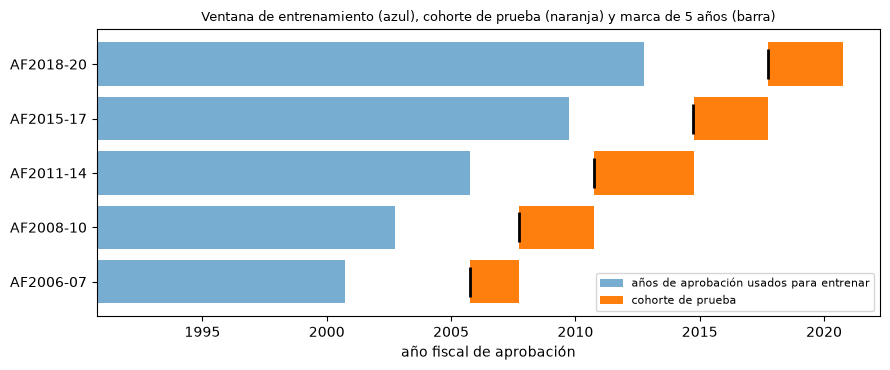

ventanas que cierran antes de su cohorte de prueba: 5 de 5
créditos de entrenamiento por ventana: [330682, 413083, 627594, 900254, 1024597]


In [3]:
# Dibujar la ventana de entrenamiento y la cohorte de prueba de cada corte, y contar las ventanas que cierran antes
fig, ax = plt.subplots(figsize=(9, 3.8))
windows = fit["cohort_windows"]
closed = 0
for k, w in enumerate(windows):
    train = w["training"]
    cutoff = date.fromisoformat(train["cutoff_date"])
    closed += int(cutoff < date(w["first_fy"] - 1, 10, 1))
    ax.barh(k, train["last_fy"] - train["first_fy"] + 1, left=train["first_fy"] - 0.25, color="tab:blue", alpha=0.6,
            label="años de aprobación usados para entrenar" if k == 0 else None)
    ax.barh(k, w["last_fy"] - w["first_fy"] + 1, left=w["first_fy"] - 0.25, color="tab:orange",
            label="cohorte de prueba" if k == 0 else None)
    mark = cutoff.year + cutoff.timetuple().tm_yday / 366
    ax.plot(mark, k, marker="|", color="black", markersize=22, markeredgewidth=2)
ax.set_yticks(range(len(windows)), [w["label"][LANG] for w in windows])
ax.set_xlabel("año fiscal de aprobación")
ax.set_title("Ventana de entrenamiento (azul), cohorte de prueba (naranja) y marca de 5 años (barra)", fontsize=9)
ax.legend(fontsize=8, loc="lower right")
fig.tight_layout()
plt.show()
print("ventanas que cierran antes de su cohorte de prueba:", closed, "de", len(windows))
print("créditos de entrenamiento por ventana:", [w["training"]["n_loans"] for w in windows])

Las cinco ventanas cierran antes de que empiece su cohorte (5 de 5): la barra negra, la marca de 5 años del último año de entrenamiento, queda un día antes de que comience la barra naranja. Los conjuntos de entrenamiento crecen de 330.682 créditos (AF1991 a AF2000) a 1.024.597, y desde el tercer corte contienen los resultados de la recesión de 2007 a 2009, razón por la cual las cohortes posteriores se comportan tan distinto de las dos primeras. La figura no muestra la regla de censura en acción, que recorta los años más recientes: la última cohorte de prueba termina en AF2020, porque la marca de 5 años de AF2021 no ha pasado a la fecha del archivo, 2026-06-30.

### Paso 2: observado frente a predicho, añada por añada

Para una añada, la PD a 5 años observada es la proporción de sus créditos que se castigó dentro de los 60 meses, y la PD a 5 años predicha es la PD media que la tarjeta de puntaje (peldaño P1) dio a sus créditos. Su diferencia es la brecha de calibración, positiva cuando el modelo subestima el riesgo y negativa cuando lo sobrestima. El AUC de la añada dice si el orden se mantuvo. La celda dibuja ambos para las quince añadas, la brecha en rojo donde el riesgo se subestimó y en azul donde se sobrestimó, e imprime los extremos.

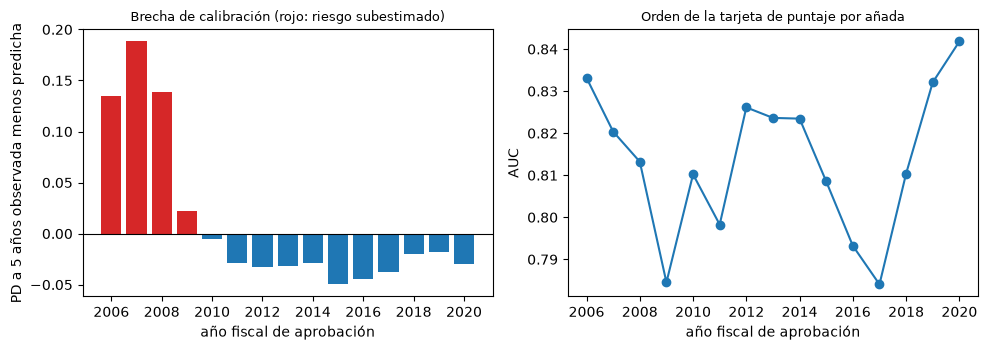

mayor brecha, año fiscal y tamaño: 2007 0.1882
añadas con el riesgo subestimado: 4 de 15
menor y mayor AUC por añada: 0.7841 0.8418


In [4]:
# PD a 5 años observada frente a predicha de las quince añadas: la brecha y el AUC de cada una
years = [v["fiscal_year"] for v in vintages]
gap = [v["observed_5y_pd"] - v["predicted_5y_pd"] for v in vintages]
aucs = [v["auc"] for v in vintages]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6))
left.bar(years, gap, color=["tab:red" if g > 0 else "tab:blue" for g in gap])
left.axhline(0, color="black", linewidth=0.8)
left.set_xlabel("año fiscal de aprobación")
left.set_ylabel("PD a 5 años observada menos predicha")
left.set_title("Brecha de calibración (rojo: riesgo subestimado)", fontsize=9)
right.plot(years, aucs, marker="o")
right.set_xlabel("año fiscal de aprobación")
right.set_ylabel("AUC")
right.set_title("Orden de la tarjeta de puntaje por añada", fontsize=9)
fig.tight_layout()
plt.show()
print("mayor brecha, año fiscal y tamaño:", years[int(np.argmax(gap))], round(max(gap), 4))
print("añadas con el riesgo subestimado:", sum(g > 0 for g in gap), "de", len(gap))
print("menor y mayor AUC por añada:", round(min(aucs), 4), round(max(aucs), 4))

La brecha es mayor en AF2007, 0,1882: los créditos aprobados ese año se castigaron cerca de 27,6% dentro de cinco años frente a 8,8% predicho. Cuatro añadas, AF2006 a AF2009, están subestimadas, y las once desde AF2010 están sobrestimadas, por hasta cinco puntos, porque las ventanas de entrenamiento de esas cohortes contienen la crisis. El AUC casi no se mueve, entre 0,7841 y 0,8418: el orden se mantiene mientras el nivel se mueve, por lo que un modelo puede conservar su AUC y estar mal dimensionado por un factor de tres. La figura muestra el problema y el signo; las pruebas del motor dicen si es lo bastante grande para rechazar.

### Paso 3: las pruebas de nivel en cada cohorte

Una cohorte tiene $N$ créditos, $D$ castigos y una PD media predicha, y los resúmenes de las añadas contienen los tres, de modo que el motor puede llamarse sobre ellos. La celda los reconstruye para cada una de las cinco cohortes y llama a la prueba de Jeffreys (Brown, Cai y DasGupta, 2001) y a la prueba binomial ajustada por Vasicek con una correlación de activos de 0,12 (BCBS, 2005), un supuesto de modelación que las filas versionadas declaran en sus notas. Ambas son de una cola: rechazan cuando los incumplimientos exceden lo que admite la PD, y una PD demasiado alta nunca se rechaza.

In [5]:
# Reconstruir N, D y la PD media de cada cohorte desde sus añadas y llamar a las dos pruebas de nivel del motor
kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    total = sum(v["n"] for v in rows)
    hits = sum(round(v["observed_5y_pd"] * v["n"]) for v in rows)
    mean_pd = sum(v["predicted_5y_pd"] * v["n"] for v in rows) / total
    jef = pd_jeffreys(total, hits, mean_pd, **kw)
    vas = pd_binomial_vasicek(total, hits, mean_pd, 0.12, **kw)
    print(n, "cohorte, créditos, castigos, PD media:", total, hits, round(mean_pd, 4))
    print("   p de Jeffreys:", round(jef.p_value, 4))
    print("   p de Vasicek y luz:", round(vas.p_value, 4), LIGHT[vas.light.value])

fy2006-07 cohorte, créditos, castigos, PD media: 174527 43581 0.0878
   p de Jeffreys: 0.0
   p de Vasicek y luz: 0.0154 ámbar
fy2008-10 cohorte, créditos, castigos, PD media: 138023 18108 0.0647
   p de Jeffreys: 0.0
   p de Vasicek y luz: 0.0845 verde
fy2011-14 cohorte, créditos, castigos, PD media: 170795 5790 0.064
   p de Jeffreys: 1.0
   p de Vasicek y luz: 0.7222 verde
fy2015-17 cohorte, créditos, castigos, PD media: 168203 6745 0.084
   p de Jeffreys: 1.0
   p de Vasicek y luz: 0.7841 verde
fy2018-20 cohorte, créditos, castigos, PD media: 136291 5256 0.0607
   p de Jeffreys: 1.0
   p de Vasicek y luz: 0.6446 verde


Las dos primeras cohortes son rechazadas por Jeffreys con un valor p de 0,0, y la prueba de Vasicek lo suaviza: ámbar para AF2006-07 (p de 0,0154) y verde para AF2008-10 (0,0845), porque una correlación de activos de 0,12 ensancha la banda de incumplimientos que una cartera puede mostrar por azar. Desde AF2011-14 el valor p de Jeffreys es 1,0 y el de Vasicek 0,7222, 0,7841 y 0,6446, todos verdes. La lectura exige cuidado: una luz verde después de 2010 significa "los incumplimientos no superan la PD", lo cual es cierto de un modelo que sobrestima por un factor de dos. La siguiente figura repite la prueba de Jeffreys añada por añada.

### Paso 4: qué añadas rechazan

Las cohortes promedian añadas que se comportan de modo muy distinto, como mostraron las figuras anteriores. `pd_jeffreys_grades` ejecuta la prueba de Jeffreys de una cola sobre cada añada por separado, con sus créditos, sus castigos y su PD media, y devuelve un resultado por añada más uno para la cohorte agrupada. La celda dibuja el valor p de cada una de las quince añadas con el color de la luz del motor, cohorte por cohorte, con un espacio entre cohortes.

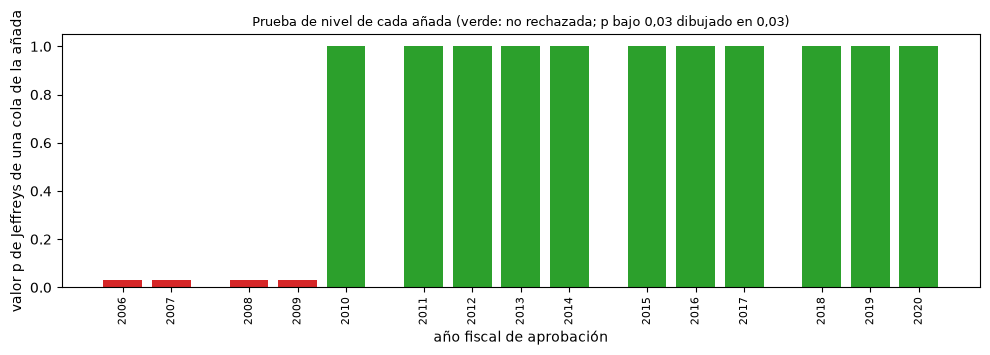

In [6]:
# La prueba de Jeffreys de una cola de cada añada, cohorte por cohorte, pintada con la luz que da el motor
colors = {"green": "tab:green", "amber": "gold", "red": "tab:red", "not_evaluated": "lightgray"}
fig, ax = plt.subplots(figsize=(10, 3.6))
position, ticks, labels_ = 0.0, [], []
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    tags = [str(v["fiscal_year"]) for v in rows]
    for r in pd_jeffreys_grades(n_v, d_v, p_v, grades=tags, policy=policy, model_id="P1-scorecard")[:-1]:
        ax.bar(position, max(r.p_value, 0.03), color=colors[r.light.value])
        ticks.append(position)
        labels_.append(r.segment)
        position += 1
    position += 0.6
ax.set_xticks(ticks, labels_, rotation=90, fontsize=8)
ax.set_xlabel("año fiscal de aprobación")
ax.set_ylabel("valor p de Jeffreys de una cola de la añada")
ax.set_title("Prueba de nivel de cada añada (verde: no rechazada; p bajo 0,03 dibujado en 0,03)", fontsize=9)
fig.tight_layout()
plt.show()

Las barras son rojas para las cuatro añadas de AF2006 a AF2009, las que tuvieron el riesgo subestimado (sus valores p son 0,0, dibujados como la barra más corta), y verdes con un valor p de 1,0 para las otras once. AF2010, en el borde, es verde. Las cohortes agrupadas del paso anterior lo desdibujaban: la cohorte AF2008-10 mezcla dos añadas rechazadas y una verde. La prueba de Jeffreys de una cola no sirve para decir que un modelo está bien calibrado después de la crisis; solo puede decir que no es demasiado optimista. Una pregunta de dos colas necesita una prueba de dos colas.

### Paso 5: pruebas de dos colas sobre las añadas de una cohorte

`pd_chi2_grades` toma los créditos, los castigos y la PD predicha de varios grupos, aquí las añadas de una cohorte, y suma las diferencias estandarizadas al cuadrado: rechaza cuando algún grupo se aleja de su PD en cualquier dirección (BCBS, 2005). `pd_traffic_lights` pinta los grupos según cuántos de ellos se alejan y cuánto, con las probabilidades del esquema supervisor de semáforo. La celda ejecuta ambas sobre las añadas de cada cohorte e imprime el valor p y la luz.

In [7]:
# Tratar las añadas de cada cohorte como grupos: el chi cuadrado de dos colas sobre añadas y la prueba de semáforo
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    chi = pd_chi2_grades(n_v, d_v, p_v, policy=policy, model_id="P1-scorecard", segment="portfolio")
    light = pd_traffic_lights(n_v, d_v, p_v, policy=policy, model_id="P1-scorecard", segment="portfolio")
    p_text = float(f"{chi.p_value:.3g}")
    print(n, "chi cuadrado sobre añadas, p y luz:", p_text, LIGHT[chi.light.value])
    print("   semáforo:", LIGHT[light.light.value])

fy2006-07 chi cuadrado sobre añadas, p y luz: 0.0 roja
   semáforo: roja
fy2008-10 chi cuadrado sobre añadas, p y luz: 0.0 roja
   semáforo: verde
fy2011-14 chi cuadrado sobre añadas, p y luz: 0.0 roja
   semáforo: verde
fy2015-17 chi cuadrado sobre añadas, p y luz: 0.0 roja
   semáforo: verde
fy2018-20 chi cuadrado sobre añadas, p y luz: 9.11e-271 roja
   semáforo: verde


El chi cuadrado sobre las añadas es rojo en las cinco cohortes, desde un valor p de 0,0 hasta 9,11e-271 para AF2018-20: es la prueba que nota la sobrestimación posterior a la crisis, por ser de dos colas. La prueba de semáforo es roja solo para AF2006-07 y verde para las demás, de modo que un esquema supervisor construido para la subestimación pasa por alto también la sobrestimación. Dos pruebas hechas para el mismo trabajo discrepan entonces en cuatro de cinco cohortes: cuál creer depende de la pregunta, y un validador que necesite saber que un modelo no es demasiado conservador debe elegir la de dos colas.

### Paso 6: las añadas como períodos consecutivos

Una cohorte de añadas consecutivas es también una serie temporal corta de tasas de incumplimiento. `pd_normal_multiperiod` toma la tasa de incumplimiento observada y la PD predicha de cada período y prueba, con una aproximación normal, si la media de las tasas observadas excede la de las PD; es de una cola. `pd_default_profile` simula el número de incumplimientos de cada grupo bajo el modelo y pregunta si el perfil observado es verosímil, en cualquier dirección. La celda ejecuta ambas en cada cohorte, con 20.000 simulaciones con semilla para el perfil.

In [8]:
# Las añadas de cada cohorte como períodos consecutivos: prueba normal multiperíodo y del perfil de incumplimientos
for n in names:
    rows = cohorts[n]["outputs"]["vintage_summary"]["rows"]
    n_v = [v["n"] for v in rows]
    d_v = [round(v["observed_5y_pd"] * v["n"]) for v in rows]
    p_v = [v["predicted_5y_pd"] for v in rows]
    rates = [v["observed_5y_pd"] for v in rows]
    kw = dict(policy=policy, model_id="P1-scorecard", segment="portfolio")
    multi = pd_normal_multiperiod(rates, p_v, **kw)
    profile = pd_default_profile(n_v, d_v, p_v, n_sim=20000, seed=1, **kw)
    print(n, "prueba normal multiperíodo, p y luz:", round(multi.p_value, 4), LIGHT[multi.light.value])
    print("   prueba del perfil de incumplimientos, p:", round(profile.p_value, 4))

fy2006-07 prueba normal multiperíodo, p y luz: 0.0 roja
   prueba del perfil de incumplimientos, p: 0.0
fy2008-10 prueba normal multiperíodo, p y luz: 0.1194 verde
   prueba del perfil de incumplimientos, p: 0.0
fy2011-14 prueba normal multiperíodo, p y luz: 1.0 verde
   prueba del perfil de incumplimientos, p: 0.0004
fy2015-17 prueba normal multiperíodo, p y luz: 1.0 verde
   prueba del perfil de incumplimientos, p: 0.0
fy2018-20 prueba normal multiperíodo, p y luz: 1.0 verde
   prueba del perfil de incumplimientos, p: 0.0


La prueba normal multiperíodo es roja solo para AF2006-07 (p de 0,0), verde para AF2008-10 (0,1194) y tiene un valor p de 1,0 después, así que se comporta como la de Jeffreys: ve solo la subestimación. La prueba del perfil de incumplimientos, que es de dos colas, da valores p de 0,0 para cuatro cohortes y 0,0004 para AF2011-14, de modo que coincide con el chi cuadrado. La familia de pruebas de dos colas es consistente y la familia de pruebas de una cola es consistente consigo misma, y son familias distintas.

### Paso 7: ¿cuántos incumplimientos son demasiados?

Una prueba de nivel es también una tolerancia: el número de incumplimientos que una cartera de $n$ créditos con PD $p$ puede mostrar antes de que la prueba rechace al 99%. Con la correlación de activos de Vasicek de 0,12, `critical_default_count` devuelve ese número. La razón entre los castigos observados y el número tolerado es menor que 1 dentro de la tolerancia y mayor que 1 fuera. La celda la calcula para las quince añadas y la dibuja, en rojo sobre 1.

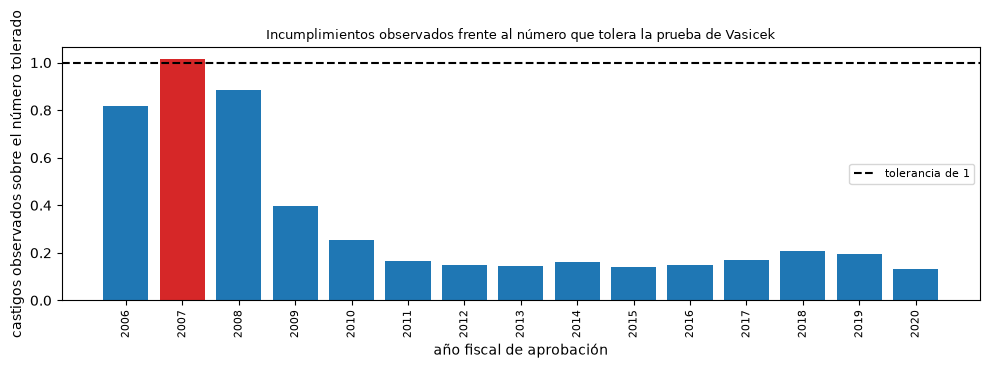

añadas sobre la tolerancia: [2007]
añada con la mayor razón, y la razón: 2007 1.014


In [9]:
# Castigos tolerados por la prueba de Vasicek (99%, correlación 0,12) en cada añada, frente a los observados
shown = np.array([round(v["observed_5y_pd"] * v["n"]) for v in vintages])
limit = np.array([critical_default_count(v["n"], v["predicted_5y_pd"], 0.99, 0.12) for v in vintages])
ratio = shown / limit
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar([str(v["fiscal_year"]) for v in vintages], ratio, color=np.where(ratio > 1, "tab:red", "tab:blue"))
ax.axhline(1, color="black", linestyle="--", label="tolerancia de 1")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.set_xlabel("año fiscal de aprobación")
ax.set_ylabel("castigos observados sobre el número tolerado")
ax.set_title("Incumplimientos observados frente al número que tolera la prueba de Vasicek", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("añadas sobre la tolerancia:", [v["fiscal_year"] for v, r in zip(vintages, ratio) if r > 1])
print("añada con la mayor razón, y la razón:", years[int(np.argmax(ratio))], round(float(ratio.max()), 3))

Solo una añada, AF2007, está sobre la tolerancia, con una razón de 1,014, y AF2006, AF2008 y las demás están dentro. La banda de la prueba de Vasicek es ancha para una cartera de este tamaño: con una correlación de 0,12 el número de incumplimientos de la cartera puede moverse decenas de por ciento sin rechazo, y 99% es el cuantil supervisor para capital, no para una validación conservadora. Las añadas que la prueba de Jeffreys rechaza con un valor p cercano a 0 quedan dentro de la tolerancia más ancha de la prueba ajustada por Vasicek, un recordatorio de que "rechazar" depende de la correlación supuesta.

### Paso 8: calibración por decil

Una cartera esconde dónde se equivoca el modelo. La calibración versionada agrupa los créditos de una cohorte en diez deciles de PD y da, para cada uno, la PD predicha, la tasa observada y un intervalo de 95% de la tasa observada. La celda cuenta, para cada cohorte, los deciles cuya PD predicha cae sobre y bajo ese intervalo, y dibuja los diez deciles de AF2015-17 en ejes logarítmicos, con la diagonal como calibración perfecta.

fy2006-07 deciles con la PD predicha sobre el intervalo: 0 | below: 10
fy2008-10 deciles con la PD predicha sobre el intervalo: 2 | below: 6
fy2011-14 deciles con la PD predicha sobre el intervalo: 9 | below: 0
fy2015-17 deciles con la PD predicha sobre el intervalo: 9 | below: 1
fy2018-20 deciles con la PD predicha sobre el intervalo: 8 | below: 2


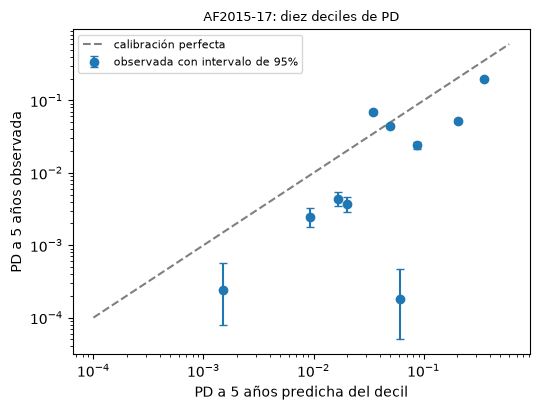

In [10]:
# Contar los deciles cuya PD predicha cae fuera del intervalo de la tasa observada, y dibujar AF2015-17
for n in names:
    rows = cohorts[n]["outputs"]["calibration"]["rows"]
    above = sum(r["predicted_pd"] > r["ci_high"] for r in rows)
    below = sum(r["predicted_pd"] < r["ci_low"] for r in rows)
    print(n, "deciles con la PD predicha sobre el intervalo:", above, "| below:", below)
rows = cohorts["fy2015-17"]["outputs"]["calibration"]["rows"]
predicted = np.array([r["predicted_pd"] for r in rows])
observed = np.array([max(r["observed_pd"], 1e-5) for r in rows])
low = np.array([max(r["ci_low"], 1e-5) for r in rows])
high = np.array([r["ci_high"] for r in rows])
fig, ax = plt.subplots(figsize=(5.5, 4.2))
err = [observed - low, high - observed]
ax.errorbar(predicted, observed, yerr=err, fmt="o", capsize=3, label="observada con intervalo de 95%")
ax.plot([1e-4, 0.6], [1e-4, 0.6], color="gray", linestyle="--", label="calibración perfecta")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("PD a 5 años predicha del decil")
ax.set_ylabel("PD a 5 años observada")
ax.set_title("AF2015-17: diez deciles de PD", fontsize=9)
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

En AF2006-07 los diez deciles están predichos bajo su intervalo (subestimados), en AF2011-14 nueve están sobre él, en AF2015-17 nueve están sobre y uno bajo, y en AF2018-20 ocho están sobre y dos bajo. En la figura de AF2015-17 los puntos quedan bajo la diagonal, y los deciles más bajos son los más lejanos: la PD predicha de los créditos más seguros es varias veces lo observado. La sobrestimación no es un desplazamiento de toda la curva sino un estiramiento de su extremo bajo. El intervalo dice cuán confiable es cada punto, y ninguno de los intervalos alcanza la diagonal en los deciles más bajos.

### Paso 9: la batería versionada, cohorte por cohorte

Los archivos de cohortes versionan la batería del motor sobre la tarjeta de puntaje. La celda dibuja la luz de seis filas de portafolio para las cinco cohortes como una grilla (verde, ámbar, rojo, gris donde la prueba solo describe) e imprime el valor p del AUC contra desarrollo, que pregunta si el orden actual cayó bajo el orden del desarrollo. Lee la grilla por columnas, como lo haría un validador, preguntando a qué cohortes objeta la batería y por qué familia de pruebas.

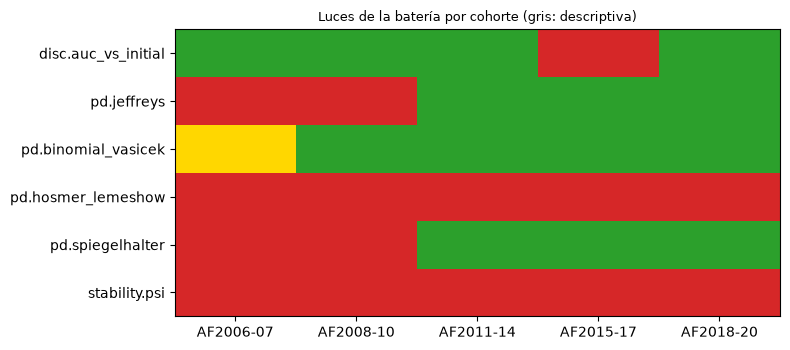

AUC contra desarrollo, p por cohorte: [1.0, 1.0, 0.977, 1.03e-08, 0.468]


In [11]:
# La batería versionada de la tarjeta de puntaje por cohorte: la luz de cada fila y el AUC contra desarrollo
show = ["disc.auc_vs_initial", "pd.jeffreys", "pd.binomial_vasicek"]
show += ["pd.hosmer_lemeshow", "pd.spiegelhalter", "stability.psi"]
codes = {"not_evaluated": 0, "green": 1, "amber": 2, "red": 3}
grid = np.zeros((len(show), len(names)))
dev_p = []
for j, n in enumerate(names):
    for i, test_id in enumerate(show):
        row = next(t for t in cohorts[n]["tests"] if t["test_id"] == test_id and t["model_id"] == "P1-scorecard"
                   and t["segment"] == "portfolio")
        grid[i, j] = codes[row["light"]]
        dev_p.append(float(f"{row['p_value']:.3g}") if test_id == "disc.auc_vs_initial" else None)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.imshow(grid, cmap=ListedColormap(["lightgray", "tab:green", "gold", "tab:red"]), vmin=0, vmax=3, aspect="auto")
ax.set_xticks(range(len(names)), [cohorts[n]["outputs"]["cohort"]["label"][LANG] for n in names])
ax.set_yticks(range(len(show)), show)
ax.set_title("Luces de la batería por cohorte (gris: descriptiva)", fontsize=9)
fig.tight_layout()
plt.show()
print("AUC contra desarrollo, p por cohorte:", [p for p in dev_p if p is not None])

## Resultados

**Respuesta:** No, y la dirección del descalce cambia: la tarjeta de puntaje subestima el riesgo de las añadas que atraviesan la crisis y sobrestima el de las posteriores. Las cinco ventanas de entrenamiento cierran antes de que empiece su cohorte de prueba (5 de 5). AF2007 se castigó 0,1882 por sobre su predicción, cuatro añadas están subestimadas y once sobrestimadas, mientras el AUC se mantiene entre 0,7841 y 0,8418. Las pruebas de una cola ven solo la primera mitad: el valor p de Jeffreys es 0,0 para AF2006-07 y AF2008-10 y 1,0 para las tres cohortes posteriores, y la prueba ajustada por Vasicek da 0,0154 (ámbar), 0,0845, 0,7222, 0,7841 y 0,6446. Las pruebas de dos colas ven ambas mitades: el chi cuadrado sobre las añadas es rojo en las cinco cohortes (9,11e-271 para AF2018-20), y la prueba del perfil de incumplimientos da 0,0 o 0,0004. Dentro de la tolerancia del paso 7 (correlación de Vasicek 0,12), solo AF2007 queda sobre ella (razón 1,014). El AUC contra desarrollo es el único rechazo en otro lugar, AF2015-17, con un valor p de 1,03e-08, donde cayó el orden y no el nivel.

Por eso un validador que ejecute solo pruebas de nivel de una cola llamaría bueno al modelo después de 2010, cuando sobrestima por un gran factor el riesgo de los créditos de los deciles de PD más bajos: nueve de diez deciles están sobre su intervalo en AF2011-14 y AF2015-17.

Lo que este notebook no muestra: las filas individuales de la batería de los otros cinco modelos, las curvas acumuladas de PD por mes, ni el efecto de reentrenar después de la crisis. Los datos son un programa federal de garantía, no la cartera pyme de un banco (hallazgo `F-DATA`), así que las cifras muestran el método sobre un panel real, no el riesgo de un prestamista particular.

## Resumen

- Un panel se valida fuera de tiempo: añadas por año fiscal de aprobación, ventanas de entrenamiento que cierran en una marca de 5 años antes de que empiece la cohorte de prueba, y un objetivo leído solo donde todo crédito ha tenido sus 60 meses.
- La calibración de una tarjeta de puntaje se mueve por cohorte: fuertemente subpredicha a través de la crisis, sobrepredicha después de ella cuando la ventana de entrenamiento contenía la crisis, mientras el AUC se mantiene entre 0,78 y 0,84.
- Las pruebas de nivel de una cola rechazan solo una subestimación; el chi cuadrado sobre las añadas, la prueba del perfil de incumplimientos y los intervalos por decil ven también la sobrestimación que inmoviliza capital.
- Una cohorte agrupada esconde lo que muestran las añadas: ejecuta la prueba de nivel por añada, y lee la tolerancia como función de la correlación supuesta.

**Qué probar a continuación.** Cambia la correlación de activos del conteo crítico de 0,12 a 0,05 o 0,20 y mira cuántas añadas salen de la tolerancia; luego continúa con el notebook 05, que aplica la misma disciplina a la PD corporativa en horizontes de uno a cinco años.

## Referencias

- U.S. Small Business Administration, 7(a) and 504 FOIA loan data (U.S. Government Works). https://data.sba.gov/dataset/7a-504-foia
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk, secciones 2.5.3.1 y 2.5.4.1 y Anexo 1 (sección 3.1). https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revisado): las pruebas binomial y binomial ajustada por Vasicek. https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Brown, L. D., Cai, T. T. y DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Este repositorio: `docs/design/SDD.md` (la división a prueba de fuga de C03) y `data-pipeline/pipeline/cases/c03/`.